# Лабораторна робота № 5

## Тема: Вступ до TensorFlow і побудова простої нейронної мережі для регресії

**Мета роботи:** навчитися створювати тензори, перевіряти їхні форму та тип даних, будувати й навчати нейронну мережу за допомогою `tf.keras.Sequential`, оцінювати якість моделі на незалежних даних, аналізувати історію навчання та зберігати модель у форматі `.keras`.

**Номер варіанта:** 7.

**Завдання варіанта:** змінити значення гіперпараметра `learning_rate` з `0.01` на `0.03` і порівняти результати з базовою моделлю.

**Використані бібліотеки:** TensorFlow, NumPy, Matplotlib.

## 1. Перевірка середовища та імпорт бібліотек

На цьому етапі підключаються необхідні бібліотеки для роботи з тензорами, створення нейронної мережі, обробки даних і побудови графіків.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

2026-10-12 23:21:06.089691: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/staslulko/Documents/GitHub/data-mining/Lab5/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Matplotlib is building the font cache; this may take a moment.


TensorFlow: 2.16.2
NumPy: 1.26.4


## 2. Створення та дослідження тензорів

Тензор є багатовимірним масивом даних. У TensorFlow можна створювати незмінні тензори за допомогою `tf.constant` і змінні за допомогою `tf.Variable`.

У цьому завданні перевіряються ранг, форма та тип даних тензора. Також розглядаються поелементні операції, матричне множення та broadcasting.

In [2]:
# Створення незмінного тензора
a = tf.constant(
    [[1., 2.],
     [3., 4.]],
    dtype=tf.float32
)

# Створення одновимірного тензора
b = tf.constant([10., 20.], dtype=tf.float32)

# Створення змінної
w = tf.Variable([0.2, 0.5])

# Зміна значень змінної
w.assign([0.3, 0.6])

# Виведення форми, типу та рангу
print("Тензор a:")
print(a)

print("Shape:", a.shape)
print("Dtype:", a.dtype)
print("Rank:", tf.rank(a).numpy())

# Додавання з використанням broadcasting
print("\na + b:")
print((a + b).numpy())

# Поелементне множення
print("\na * a:")
print((a * a).numpy())

# Матричне множення
print("\ntf.matmul(a, a):")
print(tf.matmul(a, a).numpy())

# Значення змінної
print("\nЗначення w:")
print(w.numpy())

Тензор a:
tf.Tensor(
[[1. 2.]
 [3. 4.]], shape=(2, 2), dtype=float32)
Shape: (2, 2)
Dtype: <dtype: 'float32'>
Rank: 2

a + b:
[[11. 22.]
 [13. 24.]]

a * a:
[[ 1.  4.]
 [ 9. 16.]]

tf.matmul(a, a):
[[ 7. 10.]
 [15. 22.]]

Значення w:
[0.3 0.6]


## 3. Підготовка даних для регресії

Для навчання моделі генеруються відтворювані дані, які містять лінійну залежність, синусоїдальну складову та випадковий шум.

Дані поділяються на три частини:
- **Train (70%)** — для навчання моделі.
- **Validation (15%)** — для контролю навчання та вибору моделі.
- **Test (15%)** — для остаточного оцінювання якості моделі.

Для обох моделей використовується однаковий поділ даних, що забезпечує коректність порівняння.

In [3]:
# Фіксація випадкових значень
SEED = 42

keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

# Створення вхідних даних
x = np.linspace(-5, 5, 600, dtype=np.float32)

# Додавання випадкового шуму
noise = rng.normal(0, 0.7, x.shape).astype(np.float32)

# Формування нелінійної залежності
y = 3 * x + 2 + 0.8 * np.sin(2 * x) + noise

# Перетворення даних на двовимірні масиви
x = x.reshape(-1, 1)
y = y.reshape(-1, 1)

# Перемішування даних
idx = rng.permutation(len(x))
x, y = x[idx], y[idx]

# Поділ даних: 70% / 15% / 15%
x_train, y_train = x[:420], y[:420]
x_val, y_val = x[420:510], y[420:510]
x_test, y_test = x[510:], y[510:]

# Перевірка розмірів вибірок
print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)
print("Тип даних:", x.dtype)

Train: (420, 1) (420, 1)
Validation: (90, 1) (90, 1)
Test: (90, 1) (90, 1)
Тип даних: float32


## 4. Створення та навчання базової моделі

Базова модель містить два приховані шари по 16 нейронів із функцією активації ReLU та один вихідний нейрон для числового прогнозування.

Для навчання використовується оптимізатор Adam із `learning_rate=0.01`, функція втрат MSE та метрика MAE. Модель навчається протягом 100 епох із розміром пакета 32.

In [4]:
# Функція створення базової моделі
def build_model():
    return keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(16, activation="relu"),
        layers.Dense(1)
    ])

# Створення моделі
baseline_model = build_model()

# Налаштування навчання
baseline_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="mse",
    metrics=["mae"]
)

# Перегляд архітектури
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Навчання базової моделі
baseline_history = baseline_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print(
    "Найменший val_loss базової моделі:",
    min(baseline_history.history["val_loss"])
)

Найменший val_loss базової моделі: 0.5986484289169312


## 5. Дослідження варіанта 7

Відповідно до завдання варіанта 7, змінюється лише швидкість навчання `learning_rate`. Для базової моделі вона дорівнює `0.01`, а для досліджуваної моделі становить `0.03`.

Архітектура мережі, функція втрат, метрика, кількість епох, розмір пакета та навчальні дані залишаються незмінними. Це дає змогу дослідити вплив швидкості навчання на результати нейронної мережі.

In [6]:
# Створення моделі для варіанта 7
variant_model = build_model()

# Зміна лише learning_rate
variant_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.03),
    loss="mse",
    metrics=["mae"]
)

# Перегляд архітектури
variant_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Навчання моделі варіанта 7
variant_history = variant_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)

print(
    "Найменший val_loss варіанта 7:",
    min(variant_history.history["val_loss"])
)

Найменший val_loss варіанта 7: 0.5907712578773499


## 6. Аналіз історії навчання

Для оцінювання процесу навчання будуються графіки функції втрат для навчальної та валідаційної вибірок. Порівняння кривих дає змогу оцінити швидкість збіжності моделей і виявити можливе перенавчання.

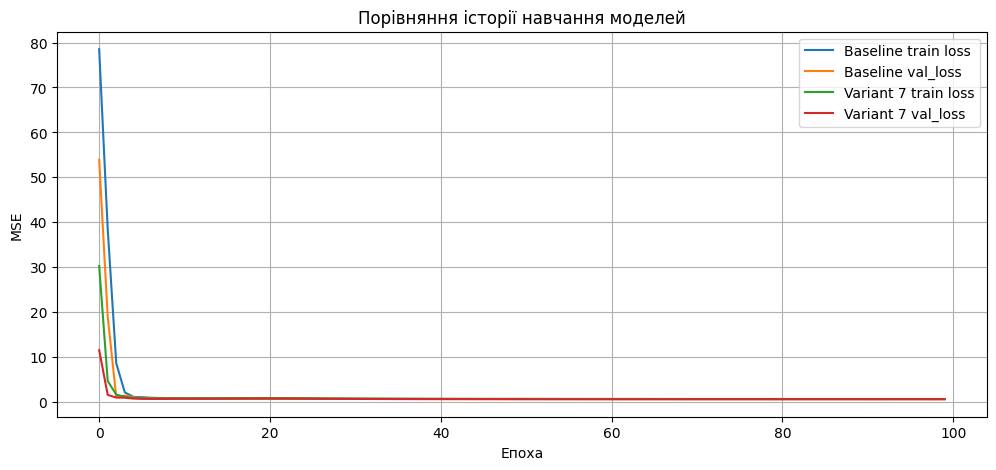

In [8]:
plt.figure(figsize=(12, 5))

# Графік базової моделі
plt.plot(
    baseline_history.history["loss"],
    label="Baseline train loss"
)
plt.plot(
    baseline_history.history["val_loss"],
    label="Baseline val_loss"
)

# Графік моделі варіанта 7
plt.plot(
    variant_history.history["loss"],
    label="Variant 7 train loss"
)
plt.plot(
    variant_history.history["val_loss"],
    label="Variant 7 val_loss"
)

plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.title("Порівняння історії навчання моделей")
plt.legend()
plt.grid(True)
plt.show()

## 7. Оцінювання якості моделей

Після вибору кращої моделі за мінімальним значенням `val_loss` виконується остаточне оцінювання на тестовій вибірці.

Використовуються дві метрики:
- **MSE** — середня квадратична помилка прогнозування.
- **MAE** — середня абсолютна помилка прогнозування.

Менші значення метрик зазвичай свідчать про точніші прогнози. Тестова вибірка використовується лише для фінального порівняння.

In [9]:
# Оцінювання базової моделі
baseline_results = baseline_model.evaluate(
    x_test, y_test, return_dict=True, verbose=0
)

# Оцінювання моделі варіанта 7
variant_results = variant_model.evaluate(
    x_test, y_test, return_dict=True, verbose=0
)

# Порівняльна таблиця
print(f"{'Модель':<20} {'Min val_loss':>15} {'Test MSE':>12} {'Test MAE':>12}")

print(
    f"{'Baseline':<20} "
    f"{min(baseline_history.history['val_loss']):>15.4f} "
    f"{baseline_results['loss']:>12.4f} "
    f"{baseline_results['mae']:>12.4f}"
)

print(
    f"{'Варіант 7':<20} "
    f"{min(variant_history.history['val_loss']):>15.4f} "
    f"{variant_results['loss']:>12.4f} "
    f"{variant_results['mae']:>12.4f}"
)

Модель                  Min val_loss     Test MSE     Test MAE
Baseline                      0.5986       0.6071       0.6143
Варіант 7                     0.5908       0.5737       0.5924


## 8. Прогнозування та вибір найкращої моделі

Найкраща модель обирається за найменшим значенням `val_loss`. Після вибору моделі виконується прогнозування для трьох нових вхідних значень: −4, 0 та 4.

Отримані результати демонструють здатність нейронної мережі прогнозувати значення досліджуваної залежності для нових вхідних даних.

In [10]:
# Вибір моделі за найменшим val_loss
baseline_val_loss = min(baseline_history.history["val_loss"])
variant_val_loss = min(variant_history.history["val_loss"])

if variant_val_loss < baseline_val_loss:
    best_model = variant_model
    best_history = variant_history
    best_name = "Варіант 7"
else:
    best_model = baseline_model
    best_history = baseline_history
    best_name = "Baseline"

print("Обрана модель:", best_name)

# Нові значення для прогнозування
x_new = np.array([[-4.], [0.], [4.]], dtype=np.float32)

# Виконання прогнозу
predictions = best_model.predict(x_new, verbose=0)

for i in range(len(x_new)):
    print(
        f"x = {x_new[i, 0]:.1f}, "
        f"прогноз y = {predictions[i, 0]:.4f}"
    )

Обрана модель: Варіант 7
x = -4.0, прогноз y = -10.1435
x = 0.0, прогноз y = 1.8947
x = 4.0, прогноз y = 14.1875


## 9. Збереження та перевірка моделі

Обрана модель зберігається у форматі `.keras`, після чого завантажується повторно. Для перевірки коректності збереження порівнюються прогнози початкової та завантаженої моделей.

Якщо прогнози збігаються в межах допустимої похибки обчислень, збереження та завантаження виконано успішно.

In [11]:
# Збереження найкращої моделі
best_model.save("lab5_model.keras")

# Завантаження моделі
restored_model = keras.models.load_model("lab5_model.keras")

# Прогнози до та після завантаження
original_predictions = best_model.predict(x_new, verbose=0)
restored_predictions = restored_model.predict(x_new, verbose=0)

print("Початкові прогнози:")
print(original_predictions)

print("\nПрогнози завантаженої моделі:")
print(restored_predictions)

# Перевірка збігу прогнозів
np.testing.assert_allclose(
    original_predictions,
    restored_predictions,
    rtol=1e-5
)

print("\nПеревірку успішно пройдено!")

Початкові прогнози:
[[-10.143514 ]
 [  1.8947077]
 [ 14.187486 ]]

Прогнози завантаженої моделі:
[[-10.143514 ]
 [  1.8947077]
 [ 14.187486 ]]

Перевірку успішно пройдено!


## Висновок

Під час виконання лабораторної роботи було розглянуто основи роботи з тензорами TensorFlow, їхні форми, типи даних і поелементні операції. Було створено набір даних для нелінійної регресії та поділено його на навчальну, валідаційну й тестову вибірки у співвідношенні 70/15/15. Побудовано та навчено базову нейронну мережу й модель для варіанта 7, у якій швидкість навчання `learning_rate` змінено з `0.01` на `0.03`. Якість моделей порівняно за значеннями `val_loss`, тестової MSE та MAE. Найкращу модель обрано за результатами валідації, після чого її було збережено у форматі `.keras` і перевірено після повторного завантаження.